<a href="https://colab.research.google.com/github/LucaWata/Calculo_Numerico/blob/main/Atividade_7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Atividade 7 - Cálculo Numérico

## Bibliotecas

In [6]:
import numpy as np
import matplotlib.pyplot as plt

## Exercício 5

Implemente o método de Gauss-Seidel em Python. Utilize como critério de parada

$$||x^{(k)} - x^{(k - 1)}||_{\infty}<10^{-5}$$

em que

$$||x^{(k)} - x^{(k-1)}||_{\infty} = \max_{i} |x_i^{(k)} - x_i^{(k-1)}|$$

Apresente o código, o número de iterações realizadas e a solução aproximada obtida.

In [7]:
A = np.array([[10.0, -1.0, 2.0],
              [-1.0, 11.0, -11.0],
              [2.0, -1.0, 10.0]])
b = np.array([6.0, 22.0, -10.0])

x = np.zeros(3)
tol = 1e-5
max_iter = 100

history_x = [x.copy()]
errors = []

k = 0
while k < max_iter:
  k += 1
  x_old = x.copy()

  x[0] = (6.0 + x[1] - 2.0 * x[2]) / 10.0
  x[1] = (22.0 + x[0] + x[2]) / 11.0
  x[2] = (-10.0 - 2.0 * x[0] + x[1]) / 10.0

  err = np.max(np.abs(x - x_old))
  history_x.append(x.copy())
  errors.append(err)

  if err < tol:
    break

print(f"Número de iterações: {k}")
print(f"Solução aproximada: x = {x[0]:.6f}, y = {x[1]:.6f}, z = {x[2]:.6f}")

Número de iterações: 6
Solução aproximada: x = 1.000000, y = 2.000000, z = -1.000000


## Exercício 6

Organize os resultados das iterações em uma tabela com as colunas:

$$k, \quad x^{(k)}, \quad y^{(k)}, \quad z^{(k)}, \quad ||x^{(k)} - x^{(k - 1)}||_{\infty}$$

In [8]:
print(f"{'k':<3} | {'x(k)':<10} | {'y(k)':<10} | {'z(k)':<10} | {'||x(k) - x(k-1)||∞':<18}")
print("-" * 60)

for k_idx, (x_val, err) in enumerate(zip(history_x[1:], errors), start=1):
    print(f"{k_idx:<3} | {x_val[0]:<10.6f} | {x_val[1]:<10.6f} | {x_val[2]:<10.6f} | {err:<18.6e}")

k   | x(k)       | y(k)       | z(k)       | ||x(k) - x(k-1)||∞
------------------------------------------------------------
1   | 0.600000   | 2.054545   | -0.914545  | 2.054545e+00      
2   | 0.988364   | 2.006711   | -0.997002  | 3.883636e-01      
3   | 1.000071   | 2.000279   | -0.999986  | 1.170777e-02      
4   | 1.000025   | 2.000004   | -1.000005  | 2.755404e-04      
5   | 1.000001   | 2.000000   | -1.000000  | 2.389216e-05      
6   | 1.000000   | 2.000000   | -1.000000  | 1.262607e-06      


## Exercício 7

Faça os seguintes gráficos usando os resultados obtidos: <br>
a) $x^{(k)}, \,y^{(k)} e \, z^{(k)}$ em função do número da iteração $k$, no mesmo gráfico; <br>
b) o erro entre iteraçõesem escala logarítmica,

$$||x^{(k)} - x^{(k - 1)}||_{\infty}$$

em função de $k$

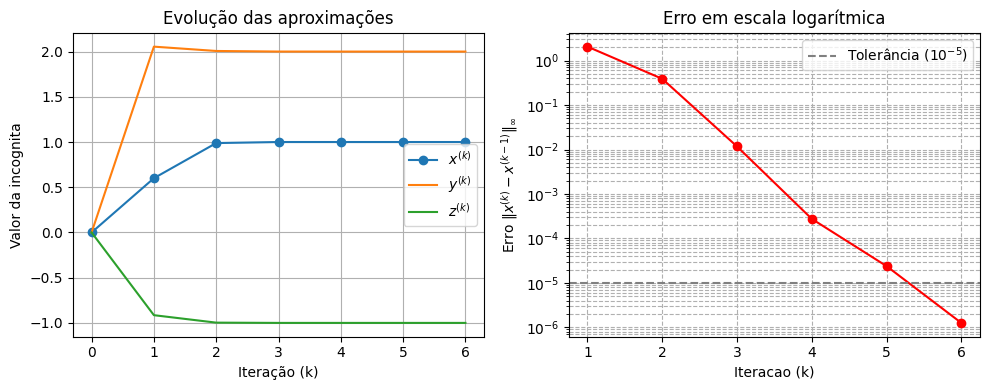

In [5]:
history_x = np.array(history_x)
iters = np.arange(len(history_x))

plt.figure(figsize = (10, 4))

plt.subplot(1, 2, 1)
plt.plot(iters, history_x[:, 0], 'o-', label = '$x^{(k)}$')
plt.plot(iters, history_x[:, 1], label = '$y^{(k)}$')
plt.plot(iters, history_x[:, 2], label = '$z^{(k)}$')
plt.xlabel('Iteração (k)')
plt.ylabel('Valor da incognita')
plt.title('Evolução das aproximações')
plt.grid(True)
plt.legend()

plt.subplot(1, 2, 2)
plt.semilogy(range(1, len(errors) + 1), errors, 'o-', color = 'red')
plt.axhline(y = 1e-5, color = 'gray', linestyle = '--', label = 'Tolerância ($10^{-5}$)')
plt.xlabel('Iteracao (k)')
plt.ylabel(r'Erro $\|x^{(k)} - x^{(k-1)}\|_{\infty}$')
plt.title('Erro em escala logarítmica')
plt.grid(True, which = "both", ls = "--")
plt.legend()

plt.tight_layout()
plt.show()